
RESULTADO DE LA SOLICITUD
Cliente: Santiago
Edad: 25
Ingresos: 3000000.0
Score: 800
Endeudamiento: 20.0 %
Monto solicitado: $ 40000000.0
Plazo solicitado: 5.0 años

DECISIÓN: REVISIÓN
EXPLICACIÓN: Índice de riesgo crediticio: 50.00/100.

CONTRAOFERTA GENERADA
Monto solicitado originalmente: $ 40000000.0
Nuevo monto sugerido: $ 28514050.82
Nuevo plazo: 6.0 años
Cuota mensual: $ 629026.76
Capacidad de pago: MEDIA
Decisión del motor para la contraoferta: APROBADO
Fitness: 0.8067
Utilidad del cliente: 0.814
Utilidad del prestamista: 0.5424


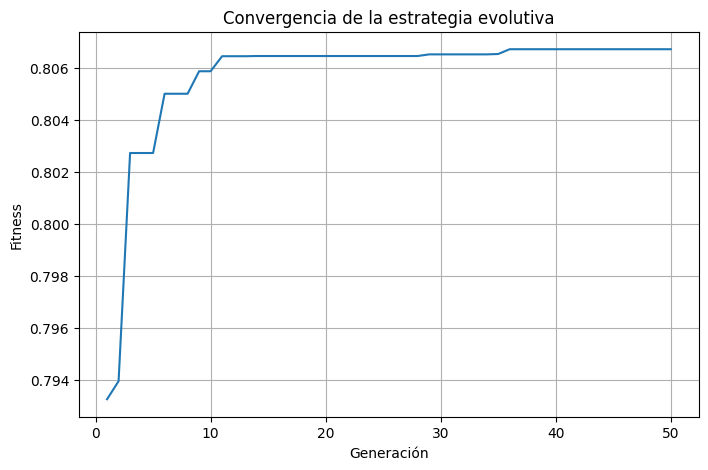

In [ ]:
import random
import matplotlib.pyplot as plt
import numpy as np

# FUNCIÓN PARA INGRESAR LOS DATOS DEL CLIENTE

def ingresar_datos():
    cliente = {}
    cliente["nombre"] = input("Nombre del cliente: ")
    cliente["edad"] = int(input("Edad del cliente: "))
    cliente["ingreso_mensual"] = float(input("Ingreso mensual: "))
    cliente["monto_credito"] = float(input("Monto solicitado: "))
    cliente["plazo"] = float(input("Plazo solicitado (años): "))
    cliente["tasa_anual"] = float(input("Tasa de interés efectiva anual (%): "))
    cliente["score"] = int(input("Score crediticio: "))
    cliente["endeudamiento"] = float(input("Nivel de endeudamiento (%): "))
    cliente["antiguedad_empleo_actual"] = float(input("Antigüedad en el empleo actual (años): "))
    cliente["reportes_negativos"] = int(input("Número de reportes negativos: "))

    if cliente["ingreso_mensual"] <= 0 or cliente["monto_credito"] <= 0:
        raise ValueError("El ingreso y el monto deben ser positivos.")
    if not 0 < cliente["plazo"] <= 20:
        raise ValueError("El plazo debe ser mayor que 0 y máximo 20 años.")
    if round(cliente["plazo"] * 12) != cliente["plazo"] * 12:
        raise ValueError("El plazo debe corresponder a meses completos (por ejemplo, 5 o 5.5 años).")
    if cliente["tasa_anual"] < 0:
        raise ValueError("La tasa efectiva anual no puede ser negativa.")
    if not 0 <= cliente["endeudamiento"] <= 100 or cliente["score"] < 0:
        raise ValueError("Revisa el score y el porcentaje de endeudamiento.")
    if cliente["reportes_negativos"] < 0 or cliente["antiguedad_empleo_actual"] < 0:
        raise ValueError("Los reportes y la antigüedad no pueden ser negativos.")
    return cliente

# EVALUAR EL SCORE CREDITICIO

def evaluar_score(score):

    if score >= 750:
        return "BUENO"

    elif score >= 550:
        return "REGULAR"

    else:
        return "MALO"


# EVALUAR EL NIVEL DE ENDEUDAMIENTO

def evaluar_endeudamiento(endeudamiento):

    if endeudamiento <= 40:
        return "BAJO"

    elif endeudamiento <= 60:
        return "MEDIO"

    else:
        return "ALTO"


# EVALUAR ESTABILIDAD LABORAL

def evaluar_estabilidad_actual(antiguedad_actual, edad):

    if 17 <= edad <= 20:

        if antiguedad_actual >= 1:
            return "ESTABLE"

        else:
            return "N/A"

    elif 21 <= edad <= 24:

        if antiguedad_actual >= 1:
            return "ESTABLE"

        else:
            return "MEDIA"

    elif 25 <= edad <= 35:

        if antiguedad_actual >= 4:
            return "ESTABLE"

        elif antiguedad_actual >= 2:
            return "MEDIA"

        else:
            return "BAJA"

    elif 36 <= edad <= 50:

        if antiguedad_actual >= 6:
            return "ESTABLE"

        elif antiguedad_actual >= 4:
            return "MEDIA"

        else:
            return "BAJA"

    elif 51 <= edad <= 65:

        if antiguedad_actual >= 8:
            return "ESTABLE"

        elif antiguedad_actual >= 6:
            return "MEDIA"

        else:
            return "BAJA"

    else:
        return "N/A"

# CONVERTIR TASA

def convertir_tasa_mensual(tasa_anual):
    tasa_decimal = tasa_anual / 100
    tasa_mensual = (1 + tasa_decimal) ** (1 / 12) - 1
    return tasa_mensual

# CALCULAR CUOTA

def calcular_cuota(monto_credito, plazo, tasa_anual):
    tasa_mensual = convertir_tasa_mensual(tasa_anual)
    meses = round(plazo * 12)
    if meses <= 0:
        raise ValueError("El plazo debe ser positivo.")
    if tasa_mensual == 0:
        return monto_credito / meses
    return monto_credito * tasa_mensual / (1 - (1 + tasa_mensual) ** (-meses))

# EVALUAR CAPACIDAD DE PAGO

def evaluar_capacidad_pago(cuota, ingreso_mensual):

    relacion = cuota / ingreso_mensual

    if 0 <= relacion <= 0.2:
        return "BUENA"

    elif 0.2 < relacion <= 0.3:
        return "MEDIA"

    elif 0.3 < relacion <= 0.4:
        return "REVISAR"

    else:
        return "BAJA"

# Funciones de pertenencia

def trimf(x, a, b, c):
    return np.interp(x, [a, b, c], [0, 1, 0])


def trapmf(x, a, b, c, d):
    return np.interp(x, [a, b, c, d], [0, 1, 1, 0])


# Conjuntos difusos de las entradas

def fuzzificar_score(score):
    return {
        "BAJO": trapmf(score, 0, 0, 500, 650),
        "MEDIO": trimf(score, 550, 700, 800),
        "ALTO": trapmf(score, 700, 800, 1000, 1000)
    }


def fuzzificar_endeudamiento(deuda):
    return {
        "BAJO": trapmf(deuda, 0, 0, 25, 45),
        "MEDIO": trimf(deuda, 30, 50, 70),
        "ALTO": trapmf(deuda, 55, 75, 100, 100)
    }


def fuzzificar_capacidad(porcentaje):
    return {
        "BAJO": trapmf(porcentaje, 0, 0, 15, 25),
        "MEDIO": trimf(porcentaje, 15, 30, 45),
        "ALTO": trapmf(porcentaje, 35, 50, 100, 100)
    }


# Conjuntos difusos de la salida (riesgo)

universo = np.linspace(0, 100, 1001)

riesgo = {
    "BAJO": trapmf(universo, 0, 0, 20, 40),
    "MEDIO": trimf(universo, 25, 50, 75),
    "ALTO": trapmf(universo, 60, 80, 100, 100)
}

# Reglas SI-ENTONCES
# Cada tupla contiene:
# (score, endeudamiento, cuota/ingreso, riesgo)

reglas = [
    # Capacidad BAJA: cuota pequeña frente al ingreso
    ("BAJO", "BAJO", "BAJO", "MEDIO"),
    ("BAJO", "MEDIO", "BAJO", "ALTO"),
    ("BAJO", "ALTO", "BAJO", "ALTO"),
    ("MEDIO", "BAJO", "BAJO", "BAJO"),
    ("MEDIO", "MEDIO", "BAJO", "MEDIO"),
    ("MEDIO", "ALTO", "BAJO", "ALTO"),
    ("ALTO", "BAJO", "BAJO", "BAJO"),
    ("ALTO", "MEDIO", "BAJO", "BAJO"),
    ("ALTO", "ALTO", "BAJO", "ALTO"),

    # Capacidad MEDIA
    ("BAJO", "BAJO", "MEDIO", "ALTO"),
    ("BAJO", "MEDIO", "MEDIO", "ALTO"),
    ("BAJO", "ALTO", "MEDIO", "ALTO"),
    ("MEDIO", "BAJO", "MEDIO", "MEDIO"),
    ("MEDIO", "MEDIO", "MEDIO", "MEDIO"),
    ("MEDIO", "ALTO", "MEDIO", "ALTO"),
    ("ALTO", "BAJO", "MEDIO", "MEDIO"),
    ("ALTO", "MEDIO", "MEDIO", "MEDIO"),
    ("ALTO", "ALTO", "MEDIO", "ALTO"),

    # Capacidad ALTA: cuota grande frente al ingreso
    ("BAJO", "BAJO", "ALTO", "ALTO"),
    ("BAJO", "MEDIO", "ALTO", "ALTO"),
    ("BAJO", "ALTO", "ALTO", "ALTO"),
    ("MEDIO", "BAJO", "ALTO", "ALTO"),
    ("MEDIO", "MEDIO", "ALTO", "ALTO"),
    ("MEDIO", "ALTO", "ALTO", "ALTO"),
    ("ALTO", "BAJO", "ALTO", "ALTO"),
    ("ALTO", "MEDIO", "ALTO", "ALTO"),
    ("ALTO", "ALTO", "ALTO", "ALTO")
]

# Inferencia Mamdani

def calcular_riesgo_difuso(cliente):

    cuota = calcular_cuota(
        cliente["monto_credito"],
        cliente["plazo"],
        cliente["tasa_anual"]
    )

    porcentaje = cuota / cliente["ingreso_mensual"] * 100

    score = fuzzificar_score(cliente["score"])
    deuda = fuzzificar_endeudamiento(cliente["endeudamiento"])
    capacidad = fuzzificar_capacidad(porcentaje)

    agregado = np.zeros_like(universo)

    for s, d, c, salida in reglas:

        # Activación de la regla (operador Y)
        activacion = min(score[s], deuda[d], capacidad[c])

        # Recortar la salida de la regla
        recorte = np.minimum(activacion, riesgo[salida])

        # Combinar con las otras reglas
        agregado = np.maximum(agregado, recorte)

    # Centroide
    area = np.trapezoid(agregado, universo)

    if area == 0:
        return 50.0

    indice = np.trapezoid(universo * agregado, universo) / area

    return float(indice)


# MOTOR DE INFERENCIA


def motor_inferencia(cliente):

    indice = calcular_riesgo_difuso(cliente)

    # Decisión según el índice de riesgo
    if indice <= 35:
        decision = "APROBADO"

    elif indice >= 65:
        decision = "RECHAZADO"

    else:
        decision = "REVISIÓN"

    explicacion = f"Índice de riesgo crediticio: {indice:.2f}/100."

    # Conservar restricciones importantes
    if cliente["reportes_negativos"] >= 2:
        decision = "RECHAZADO"
        explicacion += " Tiene dos o más reportes negativos."

    elif cliente["reportes_negativos"] == 1:
        if decision == "APROBADO":
            decision = "REVISIÓN"
        explicacion += " Tiene un reporte negativo."

    estabilidad = evaluar_estabilidad_actual(
        cliente["antiguedad_empleo_actual"],
        cliente["edad"]
    )

    if estabilidad in ["MEDIA", "BAJA"] and decision == "APROBADO":
        decision = "REVISIÓN"
        explicacion += " Requiere revisión de estabilidad laboral."

    return decision, explicacion

# MOSTRAR RESULTADOS

def mostrar_resultado(cliente, decision, explicacion):

    print("\nRESULTADO DE LA SOLICITUD")

    print("Cliente:", cliente["nombre"])
    print("Edad:", cliente["edad"])
    print("Ingresos:", cliente["ingreso_mensual"])
    print("Score:", cliente["score"])
    print("Endeudamiento:", cliente["endeudamiento"], "%")
    print("Monto solicitado: $", cliente["monto_credito"])
    print("Plazo solicitado:", cliente["plazo"], "años")

    print("\nDECISIÓN:", decision)
    print("EXPLICACIÓN:", explicacion)


# CREAR UN INDIVIDUO

def crear_individuo(cliente):
    monto_original = cliente["monto_credito"]
    meses_original = round(cliente["plazo"] * 12)
    monto = random.uniform(monto_original * 0.70, monto_original)
    meses = random.randint(meses_original, 240)
    return [monto, meses / 12]

# CREAR POBLACIÓN INICIAL

def crear_poblacion(cliente, tamaño=20):

    poblacion = []

    for i in range(tamaño):

        individuo = crear_individuo(
            cliente
        )

        poblacion.append(
            individuo
        )

    return poblacion


# CALCULAR FITNESS

def calcular_fitness(individuo, cliente):
    monto, plazo = individuo
    monto_original = cliente["monto_credito"]
    plazo_original = cliente["plazo"]
    cuota = calcular_cuota(monto, plazo, cliente["tasa_anual"])
    capacidad = max(0, min(1, 1 - cuota / cliente["ingreso_mensual"]))
    cercania_monto = max(0, min(1, monto / monto_original))
    if plazo_original == 20:
        cercania_plazo = 1
    else:
        cercania_plazo = max(0, min(1, 1 - (plazo - plazo_original) / (20 - plazo_original)))

    # Penalizar ofertas que el motor no aprobaría
    oferta = cliente.copy()
    oferta["monto_credito"] = monto
    oferta["plazo"] = plazo
    decision, _ = motor_inferencia(oferta)
    penalizacion = 0 if decision == "APROBADO" else 1
    return (0.50 * capacidad + 0.25 * cercania_monto
            + 0.25 * cercania_plazo - penalizacion)

def calcular_intereses_totales(monto, plazo, tasa_anual):

    cuota = calcular_cuota(
        monto, plazo, tasa_anual
    )

    meses = plazo * 12

    intereses = cuota * meses - monto

    return intereses

# UTILIDAD DEL CLIENTE


def utilidad_cliente(monto, plazo, cliente):

    monto_original = cliente["monto_credito"]
    plazo_original = cliente["plazo"]
    tasa_anual = cliente["tasa_anual"]

    cercania_monto = monto / monto_original

    if plazo_original == 20:
        cercania_plazo = 1
    else:
        cercania_plazo = 1 - (
            (plazo - plazo_original)
            / (20 - plazo_original)
        )

    intereses = calcular_intereses_totales(
        monto, plazo, tasa_anual
    )

    intereses_referencia = calcular_intereses_totales(
        monto_original, 20, tasa_anual
    )

    if intereses_referencia == 0:
        conveniencia_intereses = 1
    else:
        conveniencia_intereses = 1 - (
            intereses / intereses_referencia
        )

    conveniencia_intereses = max(
        0, min(1, conveniencia_intereses)
    )

    utilidad = (
        0.40 * cercania_monto
        + 0.30 * cercania_plazo
        + 0.30 * conveniencia_intereses
    )

    return utilidad

# UTILIDAD DEL PRESTAMISTA

def utilidad_prestamista(monto, plazo, cliente):

    tasa_anual = cliente["tasa_anual"]
    ingreso = cliente["ingreso_mensual"]
    monto_original = cliente["monto_credito"]

    cuota = calcular_cuota(
        monto, plazo, tasa_anual
    )

    relacion = cuota / ingreso

    capacidad = 1 - relacion
    capacidad = max(0, min(1, capacidad))

    intereses = calcular_intereses_totales(
        monto, plazo, tasa_anual
    )

    intereses_referencia = calcular_intereses_totales(
        monto_original, 20, tasa_anual
    )

    if intereses_referencia == 0:
        ingresos_intereses = 0
    else:
        ingresos_intereses = (
            intereses / intereses_referencia
        )

    ingresos_intereses = max(
        0, min(1, ingresos_intereses)
    )

    utilidad = (
        0.60 * capacidad
        + 0.40 * ingresos_intereses
    )

    return utilidad

# MUTACIÓN

def mutar(individuo, cliente):
    hijo = individuo.copy()
    hijo[0] += random.uniform(-0.05, 0.05) * cliente["monto_credito"]
    meses = round(hijo[1] * 12) + random.randint(-6, 6)
    hijo[1] = meses / 12
    return hijo

# REPARAR INDIVIDUO

def reparar(individuo, cliente):
    monto_original = cliente["monto_credito"]
    individuo[0] = max(monto_original * 0.70, min(monto_original, individuo[0]))
    meses_original = round(cliente["plazo"] * 12)
    meses = max(meses_original, min(240, round(individuo[1] * 12)))
    individuo[1] = meses / 12
    return individuo

# ESTRATEGIA EVOLUTIVA

def estrategia_evolutiva(
    cliente,
    mu=6,
    lambda_=12,
    generaciones=50
):

    historial_fitness = []

    # Crear población inicial

    poblacion = crear_poblacion(
        cliente,
        tamaño=mu
    )

    # Proceso evolutivo

    for generacion in range(
        generaciones
    ):

        # Ordenar la población de mayor a menor fitness

        poblacion.sort(
            key=lambda individuo:
            calcular_fitness(
                individuo,
                cliente
            ),
            reverse=True
        )

        # Seleccionar los mejores padres

        padres = (
            poblacion[:mu]
        )

        # Crear descendientes

        descendientes = []

        for i in range(
            lambda_
        ):

            padre = random.choice(
                padres
            )

            hijo = mutar(
                padre,
                cliente
            )

            hijo = reparar(
                hijo,
                cliente
            )

            descendientes.append(
                hijo
            )

        # Juntar padres y descendientes

        candidatos = (
            padres
            + descendientes
        )

        # Ordenar candidatos de mayor a menor fitness

        candidatos.sort(
            key=lambda individuo:
            calcular_fitness(
                individuo,
                cliente
            ),
            reverse=True
        )

        # Sobreviven los mejores individuos

        poblacion = (
            candidatos[:mu]
        )

        # Guardar el mejor fitness de la generación

        mejor_fitness_generacion = (
            calcular_fitness(
                poblacion[0],
                cliente
            )
        )

        historial_fitness.append(
            mejor_fitness_generacion
        )

    # Seleccionar el mejor individuo final

    mejor_individuo = (
        poblacion[0]
    )

    mejor_fitness = (
        calcular_fitness(
            mejor_individuo,
            cliente
        )
    )

    return (
        mejor_individuo,
        mejor_fitness,
        historial_fitness
    )


# GRAFICAR CONVERGENCIA

def graficar_convergencia(historial_fitness):

    generaciones = range(
        1,
        len(historial_fitness) + 1
    )

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        generaciones,
        historial_fitness
    )

    plt.xlabel(
        "Generación"
    )

    plt.ylabel(
        "Fitness"
    )

    plt.title(
        "Convergencia de la estrategia evolutiva"
    )

    plt.grid()

    plt.show()


# MOSTRAR CONTRAOFERTA

def mostrar_contraoferta(
    cliente,
    individuo,
    fitness
):

    monto = individuo[0]
    plazo = individuo[1]

    cuota = calcular_cuota(
    monto,
    plazo,
    cliente["tasa_anual"]
    )

    capacidad = evaluar_capacidad_pago(
    cuota,
    cliente["ingreso_mensual"]
    )

    utilidad_c = utilidad_cliente(
        monto,
        plazo,
        cliente
    )

    utilidad_p = utilidad_prestamista(
        monto,
        plazo,
        cliente
    )

    print("\nCONTRAOFERTA GENERADA")
    print("Monto solicitado originalmente: $",round(cliente["monto_credito"],2))
    print("Nuevo monto sugerido: $", round(monto, 2))
    print("Nuevo plazo:", round(plazo, 2), "años")
    print("Cuota mensual: $", round(cuota, 2))
    print("Capacidad de pago:", capacidad)
    oferta = cliente.copy()
    oferta["monto_credito"] = monto
    oferta["plazo"] = plazo
    decision_oferta, _ = motor_inferencia(oferta)
    print("Decisión del motor para la contraoferta:", decision_oferta)
    print("Fitness:",round(fitness,4))
    print("Utilidad del cliente:",round(utilidad_c,4))
    print("Utilidad del prestamista:",round(utilidad_p,4))


# 20. PROGRAMA PRINCIPAL

cliente = ingresar_datos()

decision, explicacion = (
    motor_inferencia(
        cliente
    )
)

mostrar_resultado(
    cliente,
    decision,
    explicacion
)


# ACTIVAR ESTRATEGIA EVOLUTIVA

if decision == "REVISIÓN":

    (
        mejor_individuo,
        mejor_fitness,
        historial
    ) = estrategia_evolutiva(
        cliente,
        mu=6,
        lambda_=12,
        generaciones=50
    )

    # Mostrar mejor contraoferta

    mostrar_contraoferta(
        cliente,
        mejor_individuo,
        mejor_fitness
    )

    # Mostrar curva de convergencia

    graficar_convergencia(
        historial
    )